# 03. Model Training

목적: 4개 메트릭 모델 학습 및 평가

모델:
- Steps 모델
- Kcal 모델
- Duration 모델
- Distance 모델

In [5]:
import pandas as pd
import numpy as np
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt
import seaborn as sns

# 스타일 설정
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

In [6]:
# 모델 파라미터
MODEL_PARAMS = {
    'objective': 'regression',
    'metric': 'rmse',
    'learning_rate': 0.05,
    'num_leaves': 31,
    'num_boost_round': 200,
    'verbose': -1
}

In [7]:
# 피처 정의
COMMON_FEATURES = [
    'member_count',
    'last_week_achievement_rate',
    'avg_age',
    'avg_bmi',
    'avg_resting_hr',
    'season',
    'group_weekly_active_rate'
]

STEPS_FEATURES = COMMON_FEATURES + ['group_avg_steps_14', 'user_min_steps']
KCAL_FEATURES = COMMON_FEATURES + ['group_avg_kcal_14', 'user_min_kcal']
DURATION_FEATURES = COMMON_FEATURES + ['group_avg_duration_14', 'user_min_duration']
DISTANCE_FEATURES = COMMON_FEATURES + ['group_avg_distance_14', 'user_min_distance']

print(f"피처 개수: {len(STEPS_FEATURES)}")
print(f"공통 피처 (7개): {COMMON_FEATURES}")
print(f"메트릭별 피처 (2개): group_avg_[metric]_14, user_min_[metric]")

피처 개수: 9
공통 피처 (7개): ['member_count', 'last_week_achievement_rate', 'avg_age', 'avg_bmi', 'avg_resting_hr', 'season', 'group_weekly_active_rate']
메트릭별 피처 (2개): group_avg_[metric]_14, user_min_[metric]


In [8]:
def train_and_evaluate(metric_name, features, target_col, data_path, model_path):
    """
    모델 학습 및 평가
    
    Args:
        metric_name: 메트릭 이름 (예: 'Steps')
        features: 피처 리스트
        target_col: 타겟 컬럼명
        data_path: 학습 데이터 경로
        model_path: 모델 저장 경로
    """
    print(f"\n{'='*50}")
    print(f"🚀 {metric_name} 모델 학습 시작")
    print(f"{'='*50}")
    
    # 1. 데이터 로드
    df = pd.read_csv(data_path)
    print(f"데이터 크기: {df.shape}")
    
    # 2. X, y 분리
    X = df[features]
    y = df[target_col]
    
    # 3. Train/Test 분리 (80/20)
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )
    print(f"Train: {len(X_train)}, Test: {len(X_test)}")
    
    # 4. 학습
    train_data = lgb.Dataset(X_train, label=y_train)
    test_data = lgb.Dataset(X_test, label=y_test, reference=train_data)
    
    model = lgb.train(
        MODEL_PARAMS,
        train_data,
        valid_sets=[train_data, test_data],
        valid_names=['train', 'test']
    )
    
    # 5. 예측
    y_pred_train = model.predict(X_train)
    y_pred_test = model.predict(X_test)
    
    # 6. 평가
    train_rmse = np.sqrt(mean_squared_error(y_train, y_pred_train))
    test_rmse = np.sqrt(mean_squared_error(y_test, y_pred_test))
    train_mae = mean_absolute_error(y_train, y_pred_train)
    test_mae = mean_absolute_error(y_test, y_pred_test)
    train_r2 = r2_score(y_train, y_pred_train)
    test_r2 = r2_score(y_test, y_pred_test)
    
    print(f"\n📊 평가 결과:")
    print(f"  Train RMSE: {train_rmse:.2f}")
    print(f"  Test RMSE:  {test_rmse:.2f}")
    print(f"  Train MAE:  {train_mae:.2f}")
    print(f"  Test MAE:   {test_mae:.2f}")
    print(f"  Train R²:   {train_r2:.4f}")
    print(f"  Test R²:    {test_r2:.4f}")
    
    # 7. Feature Importance
    importance = pd.DataFrame({
        'feature': features,
        'importance': model.feature_importance(importance_type='gain')
    }).sort_values('importance', ascending=False)
    
    print(f"\n🔍 Feature Importance:")
    print(importance.to_string(index=False))
    
    # 8. 모델 저장
    model.save_model(model_path)
    print(f"\n✅ 모델 저장 완료: {model_path}")
    
    # 9. 시각화
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Feature Importance
    axes[0].barh(importance['feature'], importance['importance'])
    axes[0].set_xlabel('Importance')
    axes[0].set_title(f'{metric_name} - Feature Importance')
    axes[0].invert_yaxis()
    
    # 예측 vs 실제
    axes[1].scatter(y_test, y_pred_test, alpha=0.5)
    axes[1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
    axes[1].set_xlabel('실제 값')
    axes[1].set_ylabel('예측 값')
    axes[1].set_title(f'{metric_name} - 예측 vs 실제 (Test Set)')
    
    plt.tight_layout()
    plt.show()
    
    return model, {
        'train_rmse': train_rmse,
        'test_rmse': test_rmse,
        'train_mae': train_mae,
        'test_mae': test_mae,
        'train_r2': train_r2,
        'test_r2': test_r2
    }


🚀 Steps 모델 학습 시작
데이터 크기: (38199, 10)
Train: 30559, Test: 7640

📊 평가 결과:
  Train RMSE: 1830.35
  Test RMSE:  1929.58
  Train MAE:  1418.22
  Test MAE:   1483.28
  Train R²:   0.9811
  Test R²:    0.9790

🔍 Feature Importance:
                   feature   importance
  group_weekly_active_rate 4.107865e+13
              member_count 9.785790e+12
        group_avg_steps_14 2.055817e+12
            user_min_steps 1.425109e+12
                    season 2.587956e+11
                   avg_bmi 1.145550e+10
                   avg_age 1.142339e+10
            avg_resting_hr 1.105467e+10
last_week_achievement_rate 1.017725e+10

✅ 모델 저장 완료: ../models/goal_steps_model.txt


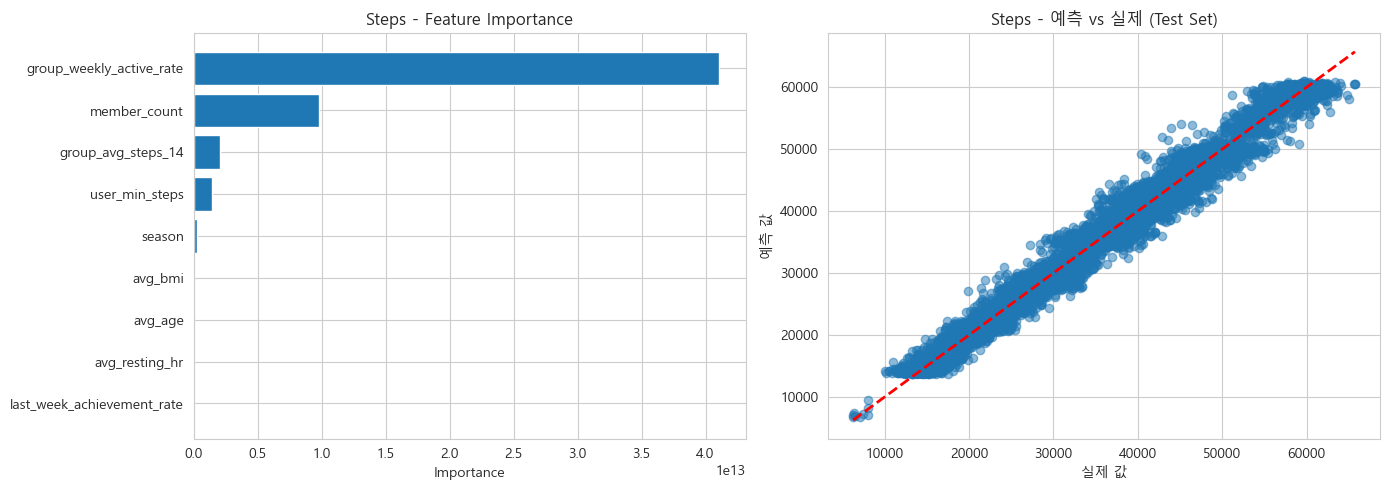

In [9]:
# 1. Steps 모델 학습
steps_model, steps_metrics = train_and_evaluate(
    metric_name='Steps',
    features=STEPS_FEATURES,
    target_col='next_goal_steps',
    data_path='../data/processed/training_steps.csv',
    model_path='../models/goal_steps_model.txt'
)


🚀 Kcal 모델 학습 시작
데이터 크기: (38199, 10)
Train: 30559, Test: 7640

📊 평가 결과:
  Train RMSE: 11.14
  Test RMSE:  11.83
  Train MAE:  8.48
  Test MAE:   8.97
  Train R²:   0.8480
  Test R²:    0.8288

🔍 Feature Importance:
                   feature   importance
              member_count 1.617828e+08
         group_avg_kcal_14 3.781265e+07
                    season 6.940376e+06
             user_min_kcal 4.514983e+06
                   avg_bmi 2.648008e+06
  group_weekly_active_rate 1.418002e+06
                   avg_age 6.816315e+05
            avg_resting_hr 6.705891e+05
last_week_achievement_rate 4.784234e+05

✅ 모델 저장 완료: ../models/goal_kcal_model.txt


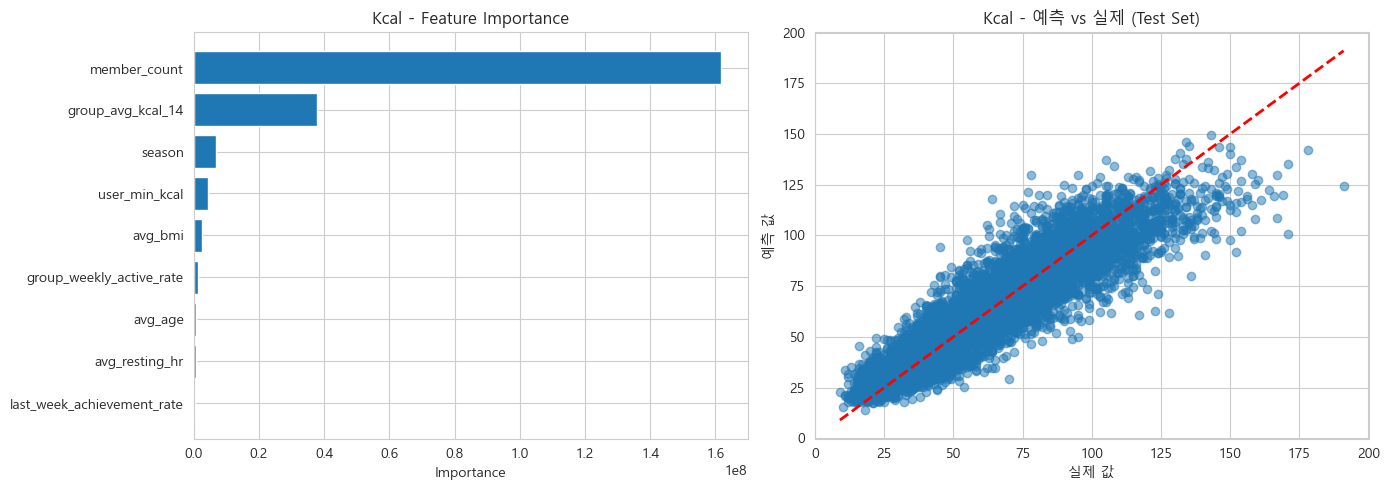

In [10]:
# 2. Kcal 모델 학습
kcal_model, kcal_metrics = train_and_evaluate(
    metric_name='Kcal',
    features=KCAL_FEATURES,
    target_col='next_goal_kcal',
    data_path='../data/processed/training_kcal.csv',
    model_path='../models/goal_kcal_model.txt'
)


🚀 Duration 모델 학습 시작
데이터 크기: (38199, 10)
Train: 30559, Test: 7640

📊 평가 결과:
  Train RMSE: 27.37
  Test RMSE:  28.70
  Train MAE:  21.43
  Test MAE:   22.40
  Train R²:   0.9316
  Test R²:    0.9250

🔍 Feature Importance:
                   feature   importance
              member_count 3.172654e+09
            avg_resting_hr 5.028523e+06
                   avg_bmi 4.952338e+06
                   avg_age 4.661992e+06
     group_avg_duration_14 4.463327e+06
last_week_achievement_rate 3.710131e+06
  group_weekly_active_rate 2.936726e+06
                    season 7.853071e+05
         user_min_duration 2.370233e+05

✅ 모델 저장 완료: ../models/goal_duration_model.txt


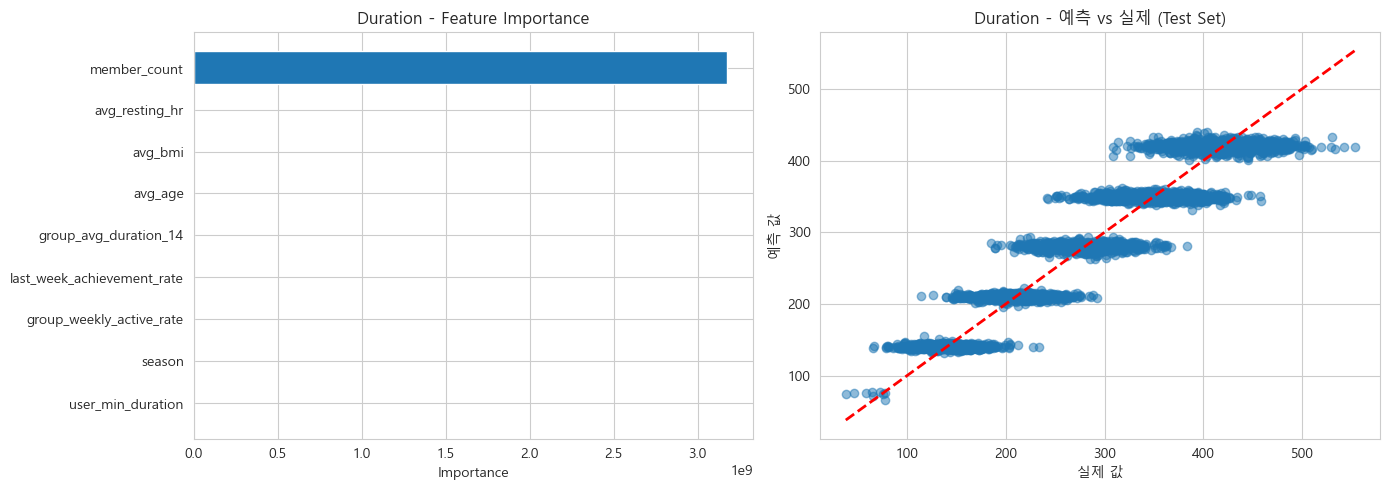

In [11]:
# 3. Duration 모델 학습
duration_model, duration_metrics = train_and_evaluate(
    metric_name='Duration',
    features=DURATION_FEATURES,
    target_col='next_goal_duration',
    data_path='../data/processed/training_duration.csv',
    model_path='../models/goal_duration_model.txt'
)


🚀 Distance 모델 학습 시작
데이터 크기: (38199, 10)
Train: 30559, Test: 7640

📊 평가 결과:
  Train RMSE: 1.47
  Test RMSE:  1.54
  Train MAE:  1.14
  Test MAE:   1.19
  Train R²:   0.9811
  Test R²:    0.9790

🔍 Feature Importance:
                   feature   importance
  group_weekly_active_rate 2.634533e+07
              member_count 6.204959e+06
     group_avg_distance_14 1.214641e+06
         user_min_distance 1.015890e+06
                    season 1.644670e+05
                   avg_bmi 7.957454e+03
                   avg_age 7.197558e+03
            avg_resting_hr 6.803908e+03
last_week_achievement_rate 6.430796e+03

✅ 모델 저장 완료: ../models/goal_distance_model.txt


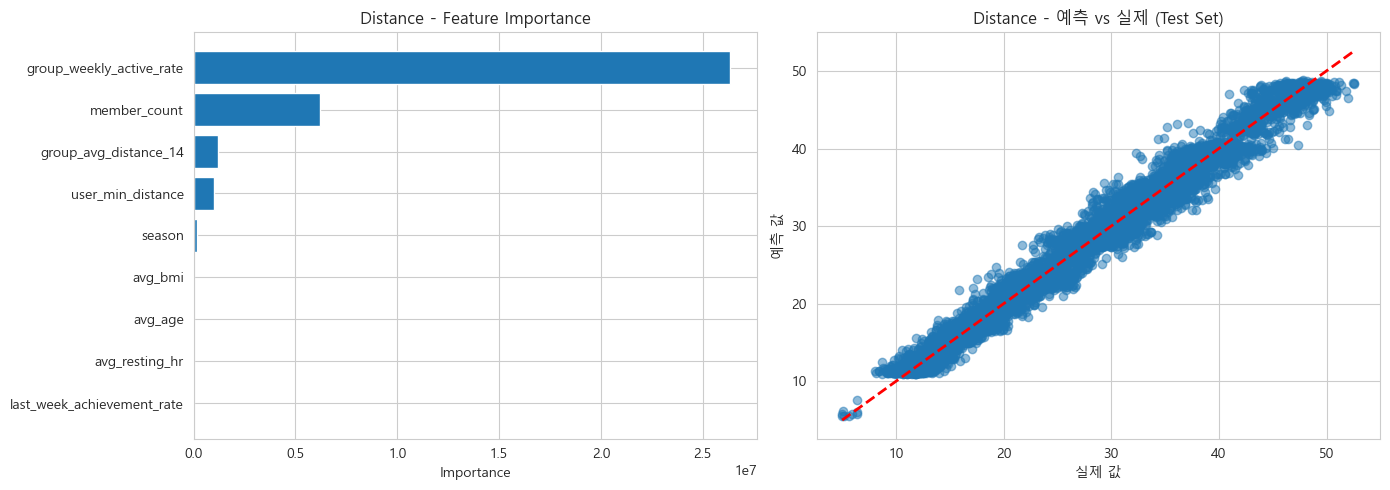

In [12]:
# 4. Distance 모델 학습
distance_model, distance_metrics = train_and_evaluate(
    metric_name='Distance',
    features=DISTANCE_FEATURES,
    target_col='next_goal_distance',
    data_path='../data/processed/training_distance.csv',
    model_path='../models/goal_distance_model.txt'
)

In [13]:
# 5. 전체 결과 요약
results_df = pd.DataFrame({
    'Model': ['Steps', 'Kcal', 'Duration', 'Distance'],
    'Test RMSE': [
        steps_metrics['test_rmse'],
        kcal_metrics['test_rmse'],
        duration_metrics['test_rmse'],
        distance_metrics['test_rmse']
    ],
    'Test MAE': [
        steps_metrics['test_mae'],
        kcal_metrics['test_mae'],
        duration_metrics['test_mae'],
        distance_metrics['test_mae']
    ],
    'Test R²': [
        steps_metrics['test_r2'],
        kcal_metrics['test_r2'],
        duration_metrics['test_r2'],
        distance_metrics['test_r2']
    ]
})

print("\n" + "="*60)
print("📈 전체 모델 성능 비교")
print("="*60)
print(results_df.to_string(index=False))
print("\n✨ 전체 학습 완료!")


📈 전체 모델 성능 비교
   Model   Test RMSE    Test MAE  Test R²
   Steps 1929.577519 1483.278683 0.978992
    Kcal   11.830570    8.971630 0.828776
Duration   28.704713   22.395751 0.925009
Distance    1.543195    1.186364 0.979005

✨ 전체 학습 완료!


In [14]:
# 6. (선택) 모델 테스트 예시

# 샘플 입력 데이터
sample_input = {
    'member_count': 4,
    'group_avg_steps_14': 8000,
    'last_week_achievement_rate': 0.95,
    'avg_age': 35,
    'avg_bmi': 23.5,
    'avg_resting_hr': 70,
    'season': 2,  # 여름
    'group_weekly_active_rate': 0.85,
    'user_min_steps': 4800
}

# Steps 예측
sample_df = pd.DataFrame([sample_input])
predicted_steps = steps_model.predict(sample_df[STEPS_FEATURES])[0]

print("\n=== 예측 테스트 (데모용) ===")
print(f"입력 데이터:")
for k, v in sample_input.items():
    print(f"  {k}: {v}")
print(f"\n예측된 다음 주 그룹 걸음수 목표: {predicted_steps:,.0f} steps")


=== 예측 테스트 (데모용) ===
입력 데이터:
  member_count: 4
  group_avg_steps_14: 8000
  last_week_achievement_rate: 0.95
  avg_age: 35
  avg_bmi: 23.5
  avg_resting_hr: 70
  season: 2
  group_weekly_active_rate: 0.85
  user_min_steps: 4800

예측된 다음 주 그룹 걸음수 목표: 29,924 steps
